## Blur

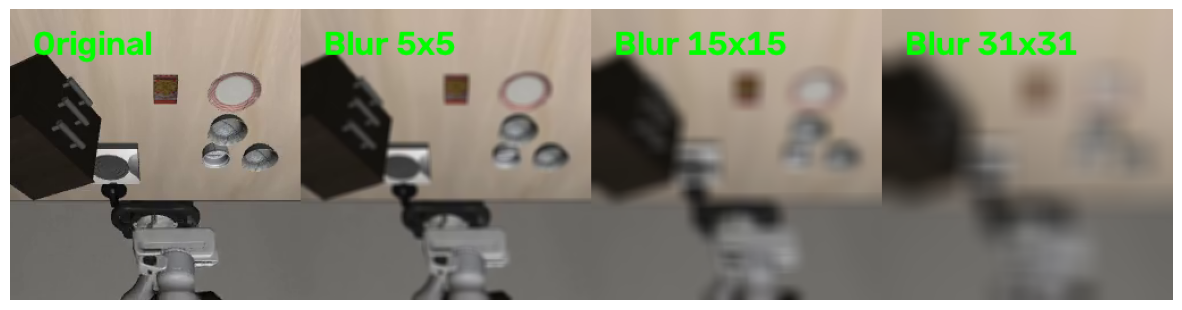

In [1]:
import cv2
import matplotlib.pyplot as plt

path_to_video = r'/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/results/videos/clean_seed42_main.mp4'
cap = cv2.VideoCapture(path_to_video)

if not cap.isOpened():
    print("Ошибка: Не удалось открыть видео.")
    exit()

target_frame_id = 10
cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_id)
ret, frame = cap.read()
cap.release()  

if not ret:
    print(f"Не удалось прочитать кадр {target_frame_id}.")
    exit()

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

blur_weak   = cv2.blur(frame_rgb, (5, 5))
blur_medium = cv2.blur(frame_rgb, (15, 15))
blur_strong = cv2.blur(frame_rgb, (31, 31))

cv2.putText(frame_rgb, "Original", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
cv2.putText(blur_weak, "Blur 5x5", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
cv2.putText(blur_medium, "Blur 15x15", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
cv2.putText(blur_strong, "Blur 31x31", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

grid_image = cv2.hconcat([frame_rgb, blur_weak, blur_medium, blur_strong])

plt.figure(figsize=(15, 5))
plt.imshow(grid_image)
plt.axis('off')
plt.show()


In [2]:
import pandas as pd

## Succes analysis

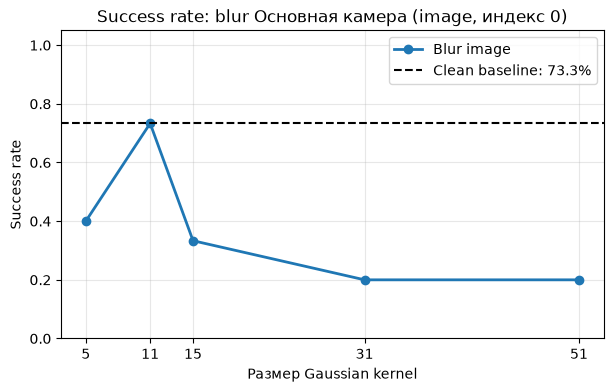

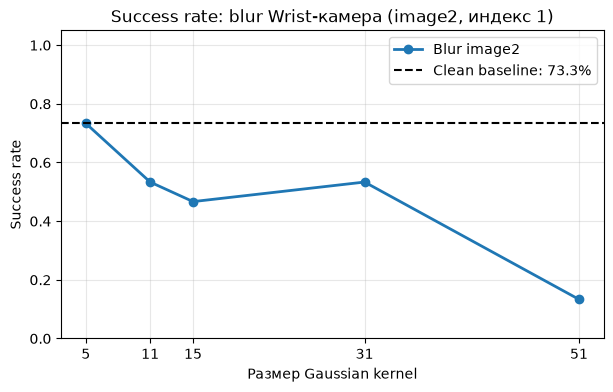

Success rate по task_id:


condition,clean,blur_5_0,blur_11_0,blur_15_0,blur_31_0,blur_51_0,blur_5_1,blur_11_1,blur_15_1,blur_31_1,blur_51_1,turnoff_0,turnoff_1
task_id,,,,,,,,,,,,,
0,33%,33%,100%,67%,67%,33%,100%,0%,33%,67%,0%,0%,0%
1,100%,33%,67%,67%,33%,0%,67%,67%,67%,0%,0%,0%,0%
2,100%,67%,100%,0%,0%,67%,33%,67%,33%,33%,33%,67%,0%
3,67%,33%,100%,33%,0%,0%,100%,33%,33%,67%,33%,0%,0%
4,67%,33%,0%,0%,0%,0%,67%,100%,67%,100%,0%,0%,0%


Общий success rate:


,condition,method,camera,kernel_size,success_rate,n_episodes
8,blur_5_0,blur,image,5.000000,40.0%,15
0,blur_11_0,blur,image,11.000000,73.3%,15
2,blur_15_0,blur,image,15.000000,33.3%,15
4,blur_31_0,blur,image,31.000000,20.0%,15
6,blur_51_0,blur,image,51.000000,20.0%,15
9,blur_5_1,blur,image2,5.000000,73.3%,15
1,blur_11_1,blur,image2,11.000000,53.3%,15
3,blur_15_1,blur,image2,15.000000,46.7%,15
5,blur_31_1,blur,image2,31.000000,53.3%,15
7,blur_51_1,blur,image2,51.000000,13.3%,15


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RESULTS_PATH = Path(
    "/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/"
    "results/visual_robustness_5tasks_3seeds_batch.csv"
)

df = pd.read_csv(RESULTS_PATH)

df["success"] = df["success"].astype(str).str.lower().eq("true")
df["task_id"] = pd.to_numeric(df["task_id"])
df["kernel_size"] = pd.to_numeric(df["kernel_size"], errors="coerce")

camera_titles = {
    "image": "Основная камера (image, индекс 0)",
    "image2": "Wrist-камера (image2, индекс 1)",
}

clean_rate = df.loc[df["method"].eq("clean"), "success"].mean()

# Две фигуры: падение success rate при blur каждой камеры.
for camera, title in camera_titles.items():
    curve = (
        df.loc[df["method"].eq("blur") & df["camera"].eq(camera)]
        .groupby("kernel_size", as_index=False)["success"]
        .agg(success_rate="mean", n="size")
        .sort_values("kernel_size")
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(
        curve["kernel_size"],
        curve["success_rate"],
        marker="o",
        linewidth=2,
        label=f"Blur {camera}",
    )
    ax.axhline(
        clean_rate,
        color="black",
        linestyle="--",
        label=f"Clean baseline: {clean_rate:.1%}",
    )

    ax.set(
        title=f"Success rate: blur {title}",
        xlabel="Размер Gaussian kernel",
        ylabel="Success rate",
        ylim=(0, 1.05),
    )
    ax.set_xticks(curve["kernel_size"])
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

# Success rate каждой condition для каждой задачи.
task_success = (
    df.groupby(["task_id", "condition"])["success"]
    .mean()
    .unstack("condition")
    .sort_index()
)

# Удобный порядок колонок.
ordered_conditions = (
    ["clean"]
    + df.loc[df["method"].eq("blur")]
        .sort_values(["camera", "kernel_size"])["condition"]
        .drop_duplicates()
        .tolist()
    + df.loc[df["method"].eq("turnoff"), "condition"].drop_duplicates().tolist()
)
task_success = task_success.reindex(columns=[c for c in ordered_conditions if c in task_success])

print("Success rate по task_id:")
display(task_success.style.format("{:.0%}"))

# Общая сводка для отправки в Colab.
overall_success = (
    df.groupby(["condition", "method", "camera", "kernel_size"])
    .agg(success_rate=("success", "mean"), n_episodes=("success", "size"))
    .reset_index()
    .sort_values(["method", "camera", "kernel_size"])
)

print("Общий success rate:")
display(overall_success.style.format({"success_rate": "{:.1%}"}))

## Attetntion analysis

Cross-attention layer: 15


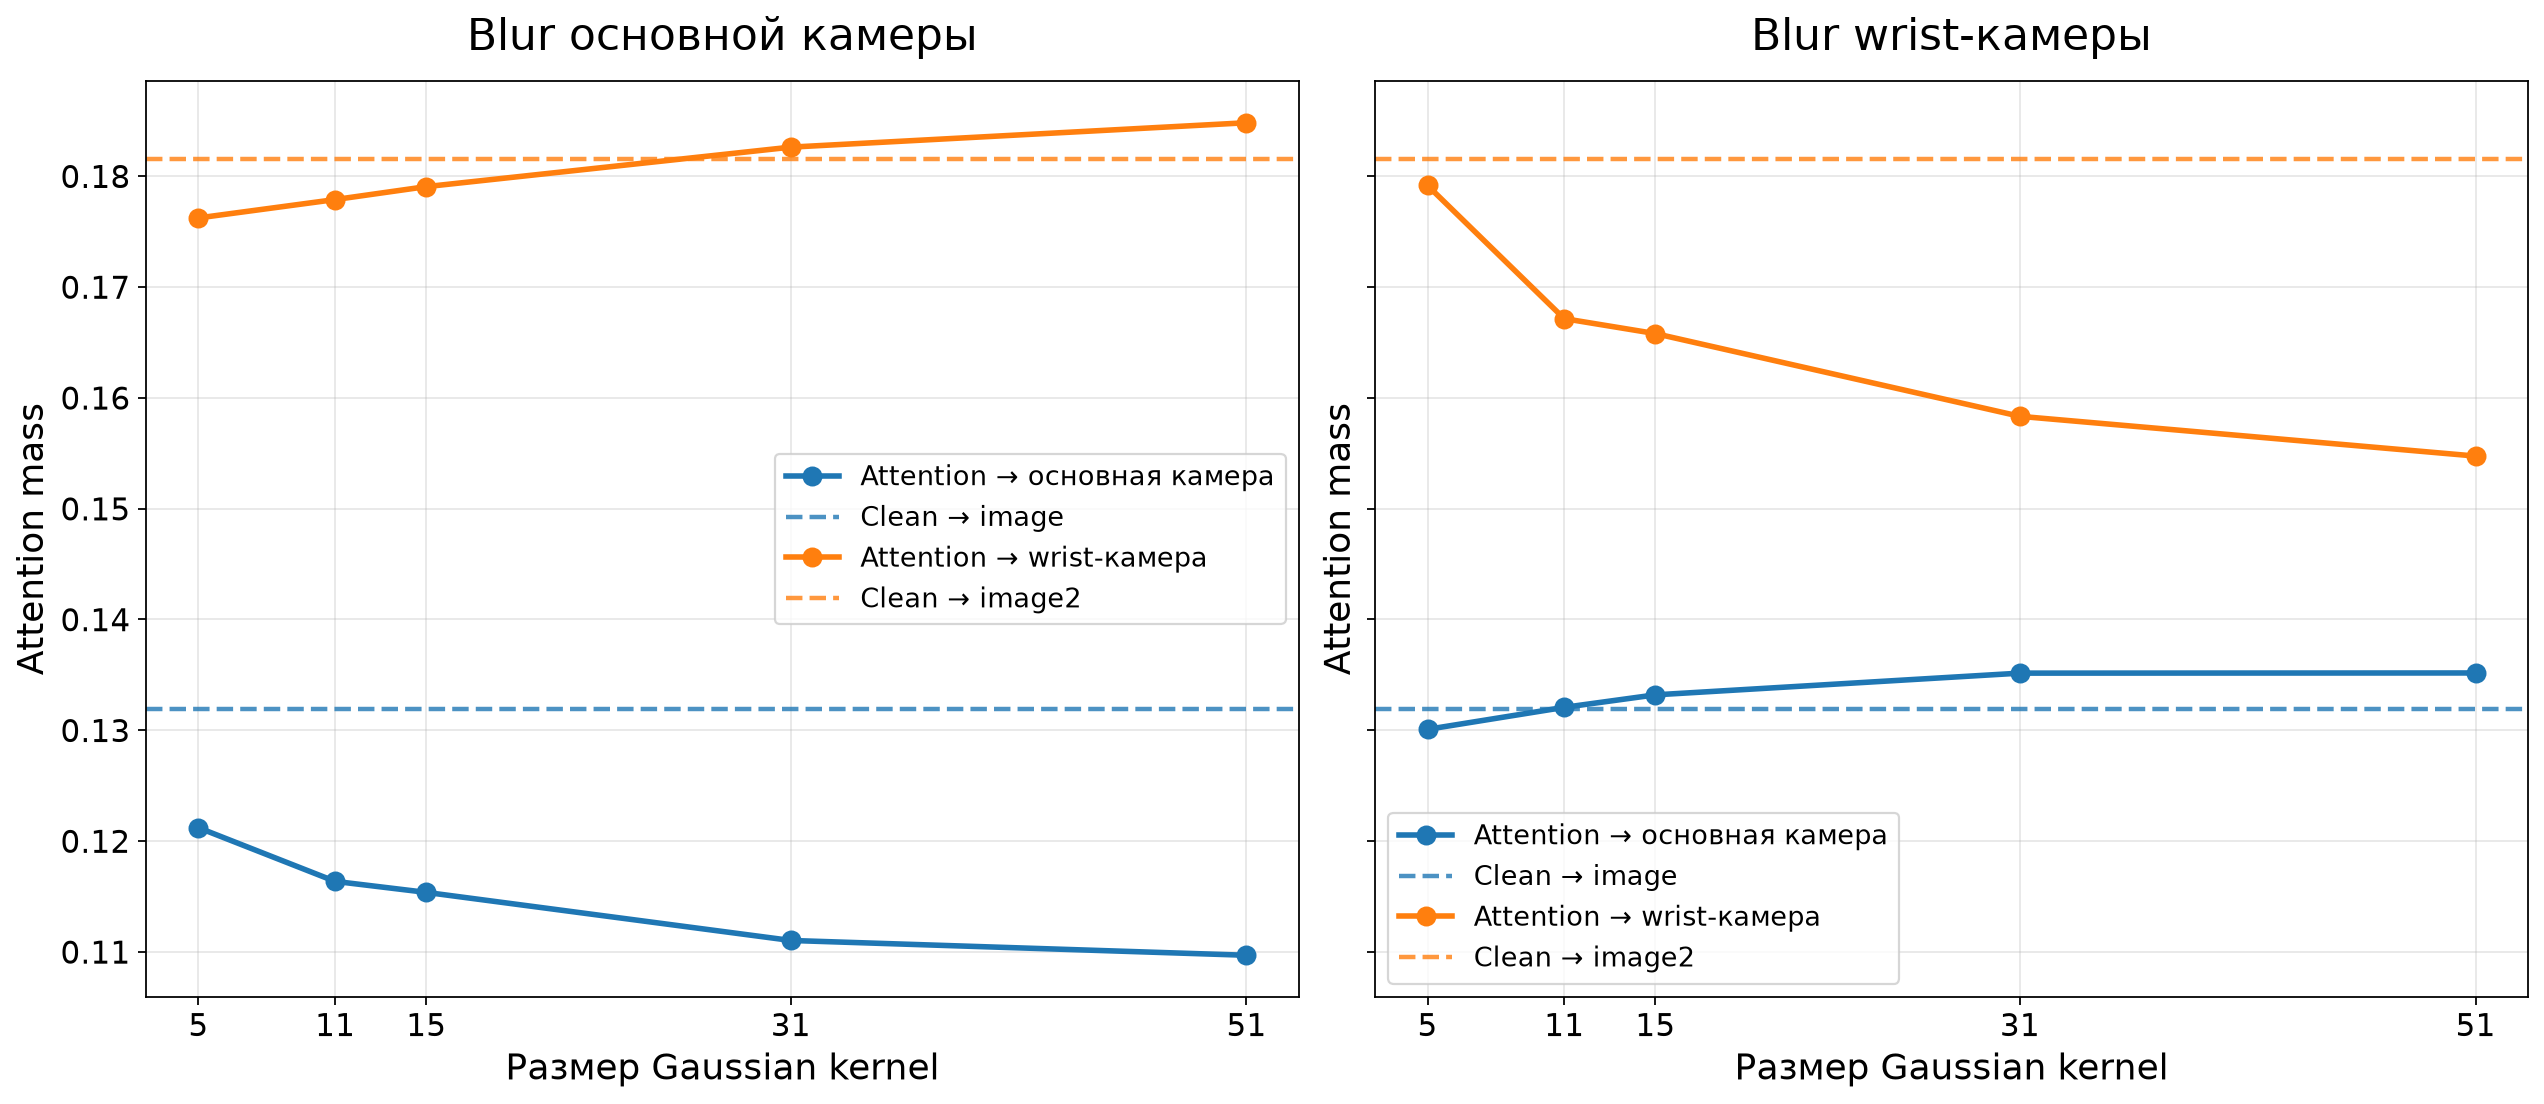

camera,condition,corrupted_camera,kernel_size,attention_to_image,attention_to_image2,delta_to_image_vs_clean,delta_to_image2_vs_clean
8,blur_5_0,image,5.000000,0.1212,0.1762,-0.0107,-0.0053
0,blur_11_0,image,11.000000,0.1164,0.1779,-0.0155,-0.0036
2,blur_15_0,image,15.000000,0.1154,0.1791,-0.0165,-0.0025
4,blur_31_0,image,31.000000,0.1110,0.1826,-0.0209,+0.0011
6,blur_51_0,image,51.000000,0.1097,0.1848,-0.0222,+0.0033
9,blur_5_0_1,"image,image2",5.000000,0.1195,0.1750,-0.0124,-0.0065
10,blur_5_1,image2,5.000000,0.1301,0.1792,-0.0018,-0.0024
1,blur_11_1,image2,11.000000,0.1321,0.1671,+0.0002,-0.0144
3,blur_15_1,image2,15.000000,0.1332,0.1658,+0.0013,-0.0157
5,blur_31_1,image2,31.000000,0.1352,0.1583,+0.0033,-0.0232


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ATTENTION_PATH = Path(
    "/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/"
    "results/attention/libero_spatial_task0_seed42.csv"
)

att = pd.read_csv(ATTENTION_PATH)

for column in ["kernel_size", "layer", "denoise_step", "head", "attention_mass"]:
    att[column] = pd.to_numeric(att[column], errors="coerce")

# Анализируем последний сохранённый cross-attention layer.
selected_layer = int(att["layer"].max())
att = att.loc[att["layer"].eq(selected_layer)].copy()

print(f"Cross-attention layer: {selected_layer}")

# attention_mass уже = sum по visual tokens камеры и mean по action queries.
# Здесь делаем mean по heads и diffusion steps.
summary = (
    att.groupby(
        ["condition", "method", "corrupted_camera", "kernel_size", "camera"],
        dropna=False,
        as_index=False,
    )["attention_mass"]
    .mean()
)

clean_baseline = (
    summary.loc[summary["condition"].eq("clean")]
    .set_index("camera")["attention_mass"]
    .to_dict()
)

camera_titles = {
    "image": "Blur основной камеры",
    "image2": "Blur wrist-камеры",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=160, sharey=True)

for ax, corrupted_camera in zip(axes, ["image", "image2"], strict=True):
    subset = summary.loc[
        summary["method"].eq("blur")
        & summary["corrupted_camera"].eq(corrupted_camera)
    ]

    for attended_camera, color, label in [
        ("image", "tab:blue", "Attention → основная камера"),
        ("image2", "tab:orange", "Attention → wrist-камера"),
    ]:
        line = (
            subset.loc[subset["camera"].eq(attended_camera)]
            .sort_values("kernel_size")
        )

        ax.plot(
            line["kernel_size"],
            line["attention_mass"],
            marker="o",
            markersize=8,
            linewidth=2.5,
            color=color,
            label=label,
        )

        ax.axhline(
            clean_baseline[attended_camera],
            color=color,
            linestyle="--",
            linewidth=2,
            alpha=0.8,
            label=f"Clean → {attended_camera}",
        )

    ax.set_title(camera_titles[corrupted_camera], fontsize=20, pad=14)
    ax.set_xlabel("Размер Gaussian kernel", fontsize=16)
    ax.set_ylabel("Attention mass", fontsize=16)
    ax.set_xticks(sorted(subset["kernel_size"].dropna().unique()))
    ax.tick_params(axis="both", labelsize=14)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

# Таблица: среднее attention к каждой камере при каждой corruption.
attention_table = (
    summary.pivot_table(
        index=["condition", "corrupted_camera", "kernel_size"],
        columns="camera",
        values="attention_mass",
    )
    .rename(
        columns={
            "image": "attention_to_image",
            "image2": "attention_to_image2",
        }
    )
    .reset_index()
)

attention_table["delta_to_image_vs_clean"] = (
    attention_table["attention_to_image"] - clean_baseline["image"]
)
attention_table["delta_to_image2_vs_clean"] = (
    attention_table["attention_to_image2"] - clean_baseline["image2"]
)

attention_table = attention_table.sort_values(
    ["corrupted_camera", "kernel_size"],
    na_position="first",
)

display(
    attention_table.style.format(
        {
            "attention_to_image": "{:.4f}",
            "attention_to_image2": "{:.4f}",
            "delta_to_image_vs_clean": "{:+.4f}",
            "delta_to_image2_vs_clean": "{:+.4f}",
        }
    )
)

## Временное отключение камеры

Каждое условие выключает только одну камеру на 20 policy-шагов. Интервалы: approach — 10–29, grasp — 40–59, transport — 60–79. Clean взят из этого же запуска.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

TEMPORARY_OFF_PATH = Path(
    '/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/'
    'results/temporary_off_single_5tasks_3seeds.csv'
)

off = pd.read_csv(TEMPORARY_OFF_PATH)
off['success'] = off['success'].astype(str).str.lower().isin(['true', '1'])

condition_info = pd.DataFrame(
    [
        ('off_approach_0', 'main', 'approach', '10–29'),
        ('off_grasp_0', 'main', 'grasp', '40–59'),
        ('off_transport_0', 'main', 'transport', '60–79'),
        ('off_approach_1', 'wrist', 'approach', '10–29'),
        ('off_grasp_1', 'wrist', 'grasp', '40–59'),
        ('off_transport_1', 'wrist', 'transport', '60–79'),
    ],
    columns=['condition', 'camera_name', 'phase', 'steps_window'],
)

clean_rate = off.loc[off['condition'].eq('clean'), 'success'].mean()
phase_order = ['approach', 'grasp', 'transport']
summary_off = (
    off.loc[off['condition'].ne('clean')]
    .merge(condition_info, on='condition', validate='many_to_one')
    .groupby(['camera_name', 'phase', 'steps_window'], as_index=False)['success']
    .agg(success_rate='mean', n_episodes='size', successes='sum')
)
summary_off['phase'] = pd.Categorical(summary_off['phase'], phase_order, ordered=True)
summary_off = summary_off.sort_values(['camera_name', 'phase'])
summary_off['delta_vs_clean_pp'] = 100 * (summary_off['success_rate'] - clean_rate)
summary_off['success_rate_pct'] = 100 * summary_off['success_rate']

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for ax, camera_name, color in zip(axes, ['main', 'wrist'], ['tab:blue', 'tab:orange'], strict=True):
    part = summary_off.loc[summary_off['camera_name'].eq(camera_name)]
    ax.plot(part['phase'], part['success_rate_pct'], marker='o', linewidth=3, markersize=9, color=color)
    ax.axhline(100 * clean_rate, color='black', linestyle='--', label=f'Clean: {100 * clean_rate:.1f}%')
    for _, row in part.iterrows():
        ax.annotate(f"{row['success_rate_pct']:.1f}%\n({row['steps_window']})",
                    (row['phase'], row['success_rate_pct']), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=11)
    ax.set(title=f'Отключение {camera_name}-камеры', xlabel='Фаза эпизода', ylim=(0, 105))
    ax.grid(axis='y', alpha=0.3)
    ax.legend()
axes[0].set_ylabel('Success rate, %')
fig.suptitle('Влияние времени временного отключения камеры', fontsize=17, y=1.02)
plt.tight_layout()
plt.show()

display(
    summary_off[['camera_name', 'phase', 'steps_window', 'successes', 'n_episodes', 'success_rate_pct', 'delta_vs_clean_pp']]
    .style.format({'success_rate_pct': '{:.1f}%', 'delta_vs_clean_pp': '{:+.1f} п.п.'})
)

# Какая задача вызывает падение для каждого временного окна.
task_table = (
    off.loc[off['condition'].ne('clean')]
    .merge(condition_info, on='condition', validate='many_to_one')
    .groupby(['task_id', 'camera_name', 'phase'])['success']
    .mean().mul(100).unstack(['camera_name', 'phase'])
    .reindex(columns=pd.MultiIndex.from_product([['main', 'wrist'], phase_order]))
)
display(task_table.style.format('{:.1f}%').set_caption('Success rate по задачам: камера × фаза отключения'))

## Attention redistribution и исход rollout

Attention-pilot содержит один rollout на condition: `task_id=0`, `seed=42`, `env_step=0`. Поэтому ниже `success` — исход одного эпизода (`0/1`), а не статистически надёжный success rate.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ATTENTION_PATH = Path('/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/results/attention/libero_spatial_task0_seed42.csv')
ROLLOUT_PATH = Path('/home/isr-lab-4/Gen_AI/smolvla-visual-robustness/results/attention/rollouts_task0_seed42.csv')

att = pd.read_csv(ATTENTION_PATH)
rollouts = pd.read_csv(ROLLOUT_PATH)
rollouts['success'] = rollouts['success'].astype(str).str.lower().isin(['true', '1'])

# Та же агрегация, что в предыдущем attention-графике: последний cross-attention layer,
# затем среднее по 15 heads и 10 denoise steps.
selected_layer = att['layer'].max()
att_last = att.loc[att['layer'].eq(selected_layer)]
camera_mass = (
    att_last.groupby(['condition', 'camera'], as_index=False)['attention_mass'].mean()
    .pivot(index='condition', columns='camera', values='attention_mass')
    .rename(columns={'image': 'attention_to_main', 'image2': 'attention_to_wrist'})
    .reset_index()
)

clean_mass = camera_mass.loc[camera_mass['condition'].eq('clean')].iloc[0]
analysis = rollouts.merge(camera_mass, on='condition', validate='one_to_one')
analysis['delta_main_vs_clean'] = analysis['attention_to_main'] - clean_mass['attention_to_main']
analysis['delta_wrist_vs_clean'] = analysis['attention_to_wrist'] - clean_mass['attention_to_wrist']

# Оставляем условия, где испорчена ровно одна камера: тогда можно однозначно назвать healthy camera.
single_camera = analysis.loc[analysis['camera'].isin(['image', 'image2']) & analysis['condition'].ne('clean')].copy()
single_camera['corrupted_view'] = single_camera['camera'].map({'image': 'main', 'image2': 'wrist'})
single_camera['delta_attention_to_corrupted'] = single_camera.apply(
    lambda row: row['delta_main_vs_clean'] if row['camera'] == 'image' else row['delta_wrist_vs_clean'],
    axis=1,
)
single_camera['delta_attention_to_healthy'] = single_camera.apply(
    lambda row: row['delta_wrist_vs_clean'] if row['camera'] == 'image' else row['delta_main_vs_clean'],
    axis=1,
)

fig, ax = plt.subplots(figsize=(11, 6))
for success, color, label in [(True, 'tab:green', 'success'), (False, 'tab:red', 'failure')]:
    part = single_camera.loc[single_camera['success'].eq(success)]
    ax.scatter(part['delta_attention_to_healthy'], part['delta_attention_to_corrupted'],
               color=color, s=90, label=label, alpha=0.85)
    for _, row in part.iterrows():
        ax.annotate(row['condition'],
                    (row['delta_attention_to_healthy'], row['delta_attention_to_corrupted']),
                    xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.axhline(0, color='black', linewidth=1, alpha=0.5)
ax.axvline(0, color='black', linewidth=1, alpha=0.5)
ax.set(
    xlabel='Δ attention к здоровой камере относительно clean',
    ylabel='Δ attention к испорченной камере относительно clean',
    title=f'Перераспределение attention, layer {selected_layer}; один rollout на condition',
)
ax.grid(alpha=0.25)
ax.legend(title='Исход rollout')
plt.show()

display(
    single_camera[[
        'condition', 'corrupted_view', 'kernel_size', 'success', 'steps',
        'delta_attention_to_corrupted', 'delta_attention_to_healthy',
    ]].sort_values(['corrupted_view', 'kernel_size'])
    .style.format({
        'delta_attention_to_corrupted': '{:+.4f}',
        'delta_attention_to_healthy': '{:+.4f}',
    })
)

## Attention по слоям и головам

Тепловые карты показывают изменение attention mass относительно clean для каждой head и каждого записанного cross-attention layer. Значение ниже нуля означает, что эта голова меньше смотрит на данную камеру, чем в clean.

In [ ]:
import numpy as np

# Сильный blur и полное выключение: четыре наиболее наглядных режима pilot.
SELECTED_CONDITIONS = ['blur_51_0', 'blur_51_1', 'turnoff_0', 'turnoff_1']

head_level = (
    att.groupby(['condition', 'layer', 'denoise_step', 'head', 'camera'], as_index=False)['attention_mass']
    .mean()
)
clean_head = (
    head_level.loc[head_level['condition'].eq('clean')]
    .rename(columns={'attention_mass': 'clean_attention_mass'})
    [['layer', 'denoise_step', 'head', 'camera', 'clean_attention_mass']]
)
deltas = head_level.merge(
    clean_head, on=['layer', 'denoise_step', 'head', 'camera'], validate='many_to_one'
)
deltas['delta_attention_mass'] = deltas['attention_mass'] - deltas['clean_attention_mass']

# Для heatmap усредняем только denoise steps. Heads и layers остаются раздельными.
heatmap_data = (
    deltas.loc[deltas['condition'].isin(SELECTED_CONDITIONS)]
    .groupby(['condition', 'camera', 'layer', 'head'], as_index=False)['delta_attention_mass']
    .mean()
)
limit = heatmap_data['delta_attention_mass'].abs().max()

fig, axes = plt.subplots(len(SELECTED_CONDITIONS), 2, figsize=(12, 17), sharex=True, sharey=True)
for row, condition in enumerate(SELECTED_CONDITIONS):
    for col, camera in enumerate(['image', 'image2']):
        ax = axes[row, col]
        matrix = (
            heatmap_data.loc[(heatmap_data['condition'].eq(condition)) & (heatmap_data['camera'].eq(camera))]
            .pivot(index='head', columns='layer', values='delta_attention_mass')
            .sort_index()
        )
        image = ax.imshow(matrix, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
        ax.set_title(f'{condition}: attention → {camera}')
        ax.set_xticks(range(len(matrix.columns)), matrix.columns)
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        if col == 0:
            ax.set_ylabel('Attention head')
        if row == len(SELECTED_CONDITIONS) - 1:
            ax.set_xlabel('Cross-attention layer')

fig.colorbar(image, ax=axes, label='Δ attention mass relative to clean', shrink=0.75)
fig.suptitle('Какие heads меняют внимание при ухудшении камеры', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

# Самые чувствительные головы: абсолютное изменение, усреднённое по двум layers и 10 denoise steps.
most_sensitive_heads = (
    heatmap_data.assign(abs_delta=lambda x: x['delta_attention_mass'].abs())
    .sort_values('abs_delta', ascending=False)
    .groupby(['condition', 'camera'], as_index=False)
    .head(5)
)
display(most_sensitive_heads.style.format({'delta_attention_mass': '{:+.4f}', 'abs_delta': '{:.4f}'}))